# Challenge 4: Web Scraping y pipeline de datos.

- **Mini pipeline:** scraping de Books to Scrape → enriquecimiento de autores con una API externa → persistencia en PostgreSQL → consultas → indexación y medición de performance.

## 1. Configuración y conexión a PostgreSQL.

### Conexión a PostgreSQL y verificación de respuesta.
- **Entrada:** credenciales del archivo .env (no se escriben en el código).
- **Salida:** imprime (1,) si la conexión funciona.
- **Entregable que cubre:** prerrequisito de la base de datos (conexión).

In [1]:
import psycopg2
from dotenv import load_dotenv
import os

load_dotenv(override=True)

conn = psycopg2.connect(
    host=os.getenv("DB_HOST"),
    port=os.getenv("DB_PORT"),
    dbname=os.getenv("DB_NAME"),
    user=os.getenv("DB_USER"),
    password=os.getenv("DB_PASSWORD")
)

cur = conn.cursor()
cur.execute("SELECT 1;")
print(cur.fetchone())
cur.close()
conn.close()

(1,)


## 2. Scraping de categorías y libros.

### 2.1. Importación de librerías y definición de funciones auxiliares del scraping.
- **Entrada:** ninguna. 
- **Salida:** constantes y funciones listas para usar.
- **Entregable que cubre:** scraping completo.

In [2]:
import re                         # expresiones regulares (limpiar el precio)
import time                       # pausas entre peticiones
import requests                   # peticiones HTTP
from bs4 import BeautifulSoup     # parseo del HTML
from urllib.parse import urljoin  # URLs absolutas a partir de relativas

BASE = "https://books.toscrape.com/"
HEADERS = {"User-Agent": "challenge4-student-project"}
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def get_soup(url):
    resp = requests.get(url, headers=HEADERS, timeout=10)
    resp.raise_for_status()
    resp.encoding = "utf-8"
    return BeautifulSoup(resp.text, "html.parser")

def parse_price(text):
    return float(re.sub(r"[^\d.]", "", text))

### 2.2. Obtención de las categorías y recorrida de todos los libros con su paginación.
- **Entrada:** URL base del sitio.
- **Salida:** lista de diccionarios, uno por libro.
- **Entregable que cubre:** scraping completo.

In [3]:
def get_categories():
    soup = get_soup(BASE + "index.html")
    links = soup.select("div.side_categories ul li ul li a")
    return [(a.get_text(strip=True), urljoin(BASE, a["href"])) for a in links]

def scrape_category(name, url):
    books = []
    while url:
        soup = get_soup(url)
        for pod in soup.select("article.product_pod"):
            a = pod.select_one("h3 a")
            rating_word = pod.select_one("p.star-rating")["class"][1]
            books.append({
                "title": a["title"],
                "price": parse_price(pod.select_one("p.price_color").get_text()),
                "rating": RATING_MAP[rating_word],
                "category": name,
                "url": urljoin(url, a["href"]),
            })
        nxt = soup.select_one("li.next a")
        url = urljoin(url, nxt["href"]) if nxt else None
        time.sleep(0.2)
    return books

### 2.3. Ejecución del scraping completo y verificación de que no falta nada.
- **Salida esperada:** 50 categorías, 1000 libros y 1000 URLs únicas.

In [4]:
all_books = []
categories = get_categories()
print("categorías:", len(categories))
for name, url in categories:
    cat_books = scrape_category(name, url)
    print(f"{name}: {len(cat_books)}")
    all_books.extend(cat_books)

print("TOTAL:", len(all_books))
print("URLs únicas:", len({b["url"] for b in all_books}))

categorías: 50
Travel: 11
Mystery: 32
Historical Fiction: 26
Sequential Art: 75
Classics: 19
Philosophy: 11
Romance: 35
Womens Fiction: 17
Fiction: 65
Childrens: 29
Religion: 7
Nonfiction: 110
Music: 13
Default: 152
Science Fiction: 16
Sports and Games: 5
Add a comment: 67
Fantasy: 48
New Adult: 6
Young Adult: 54
Science: 14
Poetry: 19
Paranormal: 1
Art: 8
Psychology: 7
Autobiography: 9
Parenting: 1
Adult Fiction: 1
Humor: 10
Horror: 17
History: 18
Food and Drink: 30
Christian Fiction: 6
Business: 12
Biography: 5
Thriller: 11
Contemporary: 3
Spirituality: 6
Academic: 1
Self Help: 5
Historical: 2
Christian: 3
Suspense: 1
Short Stories: 1
Novels: 1
Health: 4
Politics: 3
Cultural: 1
Erotica: 1
Crime: 1
TOTAL: 1000
URLs únicas: 1000


## 3. Enriquecimiento de autores con API externa

### 3.1. Cache y estructuras de trabajo
- **Entrada:** nada (usa las librerías ya importadas)
- **Salida:** sesión con cache en disco, `api_log`, `authors_cache`, `book_author_map`
- **Entregable que cubre:** cache de respuestas de la API

In [5]:
import requests_cache
from collections import Counter
from urllib.parse import quote

SESSION = requests_cache.CachedSession("api_cache")

api_log = []
authors_cache = {}
book_author_map = {}

### 3.2 Función de llamada con manejo de errores
- **Entrada:** URL y parámetros opcionales
- **Salida:** `(json, None)` si salió bien, `(None, motivo)` si falló
- **Entregable que cubre:** manejo de 404, 429 y timeout; rate limiting

In [6]:
def log_case(subject, step, reason):
    api_log.append({"subject": subject, "step": step, "reason": reason})

def api_get(url, params=None, retries=3):
    for attempt in range(retries):
        try:
            resp = SESSION.get(url, params=params, headers=HEADERS, timeout=10)
        except requests.exceptions.Timeout:
            time.sleep(attempt + 1)
            continue
        except requests.exceptions.RequestException as e:
            return None, f"error de red ({type(e).__name__})"
        if resp.status_code == 200:
            if not resp.from_cache:
                time.sleep(0.3)
            try:
                return resp.json(), None
            except ValueError:
                return None, "respuesta que no es JSON"
        if resp.status_code == 404:
            return None, "404"
        if resp.status_code == 429:
            time.sleep(2 ** (attempt + 1))
            continue
        return None, f"HTTP {resp.status_code}"
    return None, "reintentos agotados"

### 3.3 Resolver el autor a partir del título
- **Entrada:** título del libro (de Books to Scrape)
- **Salida:** `(id_autor, nombre)` o `(None, None)` si no hay coincidencia
- **Entregable que cubre:** enriquecimiento por API externa; autor no encontrado → NULL + log

In [7]:
def clean_title(title):
    title = re.sub(r"\(.*?\)", "", title)
    title = re.split(r":| - ", title)[0]
    return re.sub(r"[^a-z0-9]+", " ", title.lower()).strip()

def resolve_author(title):
    data, err = api_get(
        "https://openlibrary.org/search.json",
        params={"title": clean_title(title), "limit": 5,
                "fields": "title,author_name,author_key"},
    )
    if err:
        log_case(title, "búsqueda por título", err)
        return None, None
    for doc in data.get("docs", []):
        if (clean_title(doc.get("title", "")) == clean_title(title)
                and doc.get("author_key") and doc.get("author_name")):
            return doc["author_key"][0], doc["author_name"][0]
    log_case(title, "búsqueda por título", "sin coincidencia exacta de título")
    return None, None

### 3.4 País del autor desde Wikipedia
- **Entrada:** nombre del autor
- **Salida:** país en español, o `None` si no se puede determinar
- **Entregable que cubre:** campo país necesario para la consulta obligatoria

In [8]:
COUNTRY_PATTERNS = [
    (r"(?<!south )(?<!latin )(?<!central )\bamerican\b", "Estados Unidos"),
    (r"\b(?:british|english|scottish|welsh)\b", "Reino Unido"),
    (r"\birish\b", "Irlanda"),
    (r"\bcanadian\b", "Canadá"),
    (r"\baustralian\b", "Australia"),
    (r"\bnew zealand(?:er)?\b", "Nueva Zelanda"),
    (r"\bfrench\b", "Francia"),
    (r"\bgerman\b", "Alemania"),
    (r"\bitalian\b", "Italia"),
    (r"\bspanish\b", "España"),
    (r"\bportuguese\b", "Portugal"),
    (r"\bdutch\b", "Países Bajos"),
    (r"\bbelgian\b", "Bélgica"),
    (r"\bswiss\b", "Suiza"),
    (r"\bswedish\b", "Suecia"),
    (r"\bnorwegian\b", "Noruega"),
    (r"\bdanish\b", "Dinamarca"),
    (r"\bpolish\b", "Polonia"),
    (r"\brussian\b", "Rusia"),
    (r"\bgreek\b", "Grecia"),
    (r"\bturkish\b", "Turquía"),
    (r"\bisraeli\b", "Israel"),
    (r"\bsouth african\b", "Sudáfrica"),
    (r"\bnigerian\b", "Nigeria"),
    (r"\bindian\b", "India"),
    (r"\bchinese\b", "China"),
    (r"\bjapanese\b", "Japón"),
    (r"\bmexican\b", "México"),
    (r"\bargentin(?:e|ian)\b", "Argentina"),
    (r"\bbrazilian\b", "Brasil"),
    (r"\bchilean\b", "Chile"),
    (r"\bcolombian\b", "Colombia"),
    (r"\bcuban\b", "Cuba"),
]
COUNTRY_REGEX = [(re.compile(p, re.I), c) for p, c in COUNTRY_PATTERNS]

def find_country(text):
    best = None
    for pattern, country in COUNTRY_REGEX:
        m = pattern.search(text)
        if m and (best is None or m.start() < best[0]):
            best = (m.start(), country)
    return best[1] if best else None

def fetch_country(name):
    page = quote(name.strip().rstrip(".").replace(" ", "_"), safe="")
    data, err = api_get(f"https://en.wikipedia.org/api/rest_v1/page/summary/{page}")
    if err:
        log_case(name, "Wikipedia", err)
        return None
    if data.get("type") == "disambiguation":
        log_case(name, "Wikipedia", "página de desambiguación")
        return None
    country = find_country(data.get("description") or "")
    if country is None:
        country = find_country((data.get("extract") or "").split(". ")[0])
    if country is None:
        log_case(name, "Wikipedia", "no se encontró nacionalidad en el texto")
    return country

### 3.5 Ficha del autor y enriquecimiento de todos los libros
- **Entrada:** lista `all_books`
- **Salida:** `authors_cache` (fichas por autor) y `book_author_map` (libro → autor)
- **Entregable que cubre:** enriquecimiento con ≥2 datos nuevos, cache, idempotencia

In [9]:
def build_author(key, name):
    ficha = {"name": name, "birth_year": None, "country": None,
             "external_api_id": key, "total_known_works": None,
             "api_source": "Open Library"}
    data, err = api_get(f"https://openlibrary.org/authors/{key}.json")
    if err:
        log_case(name, "Open Library autor", err)
    else:
        m = re.search(r"\b(\d{4})\b", str(data.get("birth_date", "")))
        if m:
            ficha["birth_year"] = int(m.group(1))
    works, err = api_get(f"https://openlibrary.org/authors/{key}/works.json",
                         params={"limit": 1})
    if err:
        log_case(name, "Open Library obras", err)
    else:
        ficha["total_known_works"] = works.get("size")
    ficha["country"] = fetch_country(name)
    if ficha["country"]:
        ficha["api_source"] = "Open Library + Wikipedia"
    return ficha

def run_enrichment(books):
    pending = [b for b in books if b["url"] not in book_author_map]
    for i, book in enumerate(pending, 1):
        key, name = resolve_author(book["title"])
        if key and key not in authors_cache:
            authors_cache[key] = build_author(key, name)
        book_author_map[book["url"]] = key
        if i % 50 == 0:
            print(f"  {i}/{len(pending)} libros procesados")
    print("listo:", len(book_author_map), "libros,", len(authors_cache), "autores")

### 3.6 Ejecución y verificación
- **Entrada:** `all_books`
- **Salida:** resumen, muestra de fichas y motivos del log
- **Entregable que cubre:** evidencia de que los datos vienen de la API y del manejo de errores

In [10]:
run_enrichment(all_books)

  50/1000 libros procesados
  100/1000 libros procesados
  150/1000 libros procesados
  200/1000 libros procesados
  250/1000 libros procesados
  300/1000 libros procesados
  350/1000 libros procesados
  400/1000 libros procesados
  450/1000 libros procesados
  500/1000 libros procesados
  550/1000 libros procesados
  600/1000 libros procesados
  650/1000 libros procesados
  700/1000 libros procesados
  750/1000 libros procesados
  800/1000 libros procesados
  850/1000 libros procesados
  900/1000 libros procesados
  950/1000 libros procesados
  1000/1000 libros procesados
listo: 1000 libros, 704 autores


In [11]:
con_autor = sum(1 for v in book_author_map.values() if v)
print("libros con autor:", con_autor, "| sin autor (NULL):", len(book_author_map) - con_autor)
print("autores:", len(authors_cache), "| con país:", sum(1 for a in authors_cache.values() if a["country"]))
print("casos en el log:", len(api_log))
print()
for ficha in list(authors_cache.values())[:5]:
    print(ficha)
print()
print(Counter(c["reason"] for c in api_log))

libros con autor: 837 | sin autor (NULL): 163
autores: 704 | con país: 473
casos en el log: 394

{'name': 'Rolf Potts', 'birth_year': None, 'country': 'Estados Unidos', 'external_api_id': 'OL2839167A', 'total_known_works': 10, 'api_source': 'Open Library + Wikipedia'}
{'name': 'Frances Mayes', 'birth_year': 1940, 'country': 'Estados Unidos', 'external_api_id': 'OL20984A', 'total_known_works': 47, 'api_source': 'Open Library + Wikipedia'}
{'name': 'Marilyn Brant', 'birth_year': None, 'country': None, 'external_api_id': 'OL6792839A', 'total_known_works': 14, 'api_source': 'Open Library'}
{'name': 'Paul Theroux', 'birth_year': 1941, 'country': 'Estados Unidos', 'external_api_id': 'OL4416468A', 'total_known_works': 266, 'api_source': 'Open Library + Wikipedia'}
{'name': 'Peter Mayle', 'birth_year': 1939, 'country': 'Reino Unido', 'external_api_id': 'OL29023A', 'total_known_works': 240, 'api_source': 'Open Library + Wikipedia'}

Counter({'sin coincidencia exacta de título': 163, '404': 131,

## 4. Modelo relacional y carga en PostgreSQL

### 4.1 Creación de tablas
- **Entrada:** nada (usa la conexión definida en la sección 1)
- **Salida:** tablas categories, authors, books, book_authoryenrichment_log, con PK, FK, restricciones e índices
- **Entregable que cubre:** modelo relacional con relación N:M libros↔autores

In [12]:
DDL = """
DROP TABLE IF EXISTS enrichment_log, book_author, books, authors, categories CASCADE;

CREATE TABLE IF NOT EXISTS categories (
    id          SERIAL PRIMARY KEY,
    name        TEXT NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS authors (
    id                SERIAL PRIMARY KEY,
    name              TEXT NOT NULL,
    birth_year        INTEGER,
    country           TEXT,
    external_api_id   TEXT NOT NULL UNIQUE,
    total_known_works INTEGER,
    api_source        TEXT NOT NULL,
    created_at        TIMESTAMP NOT NULL DEFAULT NOW()
);

CREATE TABLE IF NOT EXISTS books (
    id          SERIAL PRIMARY KEY,
    title       TEXT NOT NULL,
    price       NUMERIC(6,2) NOT NULL CHECK (price >= 0),
    rating      SMALLINT NOT NULL CHECK (rating BETWEEN 1 AND 5),
    category_id INTEGER NOT NULL REFERENCES categories (id),
    url         TEXT NOT NULL UNIQUE
);

CREATE TABLE IF NOT EXISTS book_author (
    book_id   INTEGER NOT NULL REFERENCES books (id),
    author_id INTEGER NOT NULL REFERENCES authors (id),
    PRIMARY KEY (book_id, author_id)
);

CREATE TABLE IF NOT EXISTS enrichment_log (
    id      SERIAL PRIMARY KEY,
    subject TEXT NOT NULL,
    step    TEXT NOT NULL,
    reason  TEXT NOT NULL,
    UNIQUE (subject, step, reason)
);

-- Índices sobre columnas de FK y de filtro frecuente.
-- (El índice de book_author.author_id NO se crea acá: se crea a propósito en la sección 6
--  para medir el rendimiento antes y después.)
CREATE INDEX IF NOT EXISTS idx_books_category_id ON books (category_id);
CREATE INDEX IF NOT EXISTS idx_books_rating      ON books (rating);
"""

def get_conn():
    return psycopg2.connect(host=os.getenv("DB_HOST"), port=os.getenv("DB_PORT"),
                            dbname=os.getenv("DB_NAME"), user=os.getenv("DB_USER"),
                            password=os.getenv("DB_PASSWORD"))

conn = get_conn()
with conn, conn.cursor() as cur:
    cur.execute(DDL)
conn.close()
print("tablas listas")

tablas listas


### 4.2 Carga idempotente de los datos
- **Entrada:** `all_books`, `authors_cache`, `book_author_map`, `api_log`
- **Salida:** filas insertadas en las cinco tablas, sin duplicar si se vuelve a ejecutar
- **Entregable que cubre:** persistencia en PostgreSQL, N:M, autores no encontrados registrados

In [13]:
conn = get_conn()
with conn, conn.cursor() as cur:
    for name in sorted({b["category"] for b in all_books}):
        cur.execute("INSERT INTO categories (name) VALUES (%s) ON CONFLICT (name) DO NOTHING", (name,))
    cur.execute("SELECT name, id FROM categories")
    category_id = dict(cur.fetchall())

    for a in authors_cache.values():
        cur.execute("""
            INSERT INTO authors (name, birth_year, country, external_api_id, total_known_works, api_source)
            VALUES (%(name)s, %(birth_year)s, %(country)s, %(external_api_id)s, %(total_known_works)s, %(api_source)s)
            ON CONFLICT (external_api_id) DO NOTHING
        """, a)
    cur.execute("SELECT external_api_id, id FROM authors")
    author_id = dict(cur.fetchall())

    for b in all_books:
        cur.execute("""
            INSERT INTO books (title, price, rating, category_id, url)
            VALUES (%s, %s, %s, %s, %s)
            ON CONFLICT (url) DO NOTHING
        """, (b["title"], b["price"], b["rating"], category_id[b["category"]], b["url"]))
    cur.execute("SELECT url, id FROM books")
    book_id = dict(cur.fetchall())

    for url, key in book_author_map.items():
        if key:
            cur.execute("""
                INSERT INTO book_author (book_id, author_id) VALUES (%s, %s)
                ON CONFLICT DO NOTHING
            """, (book_id[url], author_id[key]))

    for c in api_log:
        cur.execute("""
            INSERT INTO enrichment_log (subject, step, reason) VALUES (%s, %s, %s)
            ON CONFLICT DO NOTHING
        """, (c["subject"], c["step"], c["reason"]))
conn.close()
print("carga lista")

carga lista


### 4.3 Verificación de la carga
- **Entrada:** nada
- **Salida:** cantidad de filas por tabla y libros sin autor
- **Entregable que cubre:** evidencia de la persistencia

In [14]:
conn = get_conn()
cur = conn.cursor()
for table in ["categories", "authors", "books", "book_author", "enrichment_log"]:
    cur.execute(f"SELECT COUNT(*) FROM {table}")
    print(f"{table:15} {cur.fetchone()[0]}")
cur.execute("""
    SELECT COUNT(*) FROM books b
    LEFT JOIN book_author ba ON ba.book_id = b.id
    WHERE ba.book_id IS NULL
""")
print("libros sin autor:", cur.fetchone()[0])
cur.close()
conn.close()

categories      50
authors         704
books           1000
book_author     837
enrichment_log  394
libros sin autor: 163


### 4.4 Diagrama UML
- **Entrada:** estructura de las tablas creadas en 4.1
- **Salida:** diagrama de entidad-relación del modelo (categories, books, authors, book_author, enrichment_log)
- **Entregable que cubre:** diagrama UML obligatorio

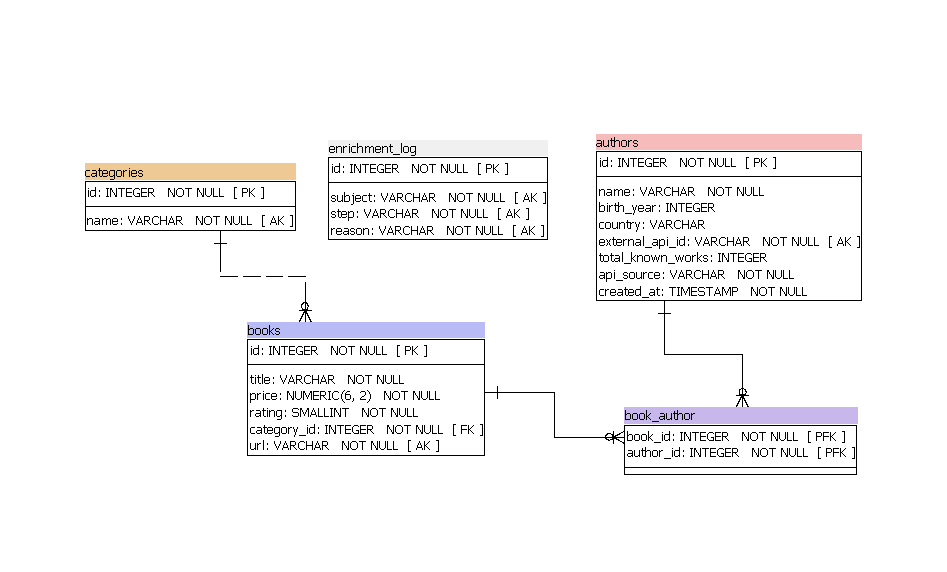

## 5. Consultas SQL

### 5.1 Función auxiliar para ejecutar consultas
- **Entrada:** texto de una consulta SQL
- **Salida:** columnas y filas impresas, con NULL visible
- **Entregable que cubre:** ejecución de las consultas sobre la base

In [15]:
def run_query(sql):
    conn = get_conn()
    cur = conn.cursor()
    cur.execute(sql)
    cols = [d[0] for d in cur.description]
    rows = cur.fetchall()
    cur.close()
    conn.close()
    print(" | ".join(cols))
    print("-" * 70)
    for r in rows:
        print(" | ".join("NULL" if v is None else str(v) for v in r))
    print(f"({len(rows)} filas)")

### 5.2 Libros con más de 3 estrellas por menos de £10
- **Entrada:** tablas `books` y `categories`
- **Salida:** lista de libros de 4 o 5 estrellas con precio menor a £10
- **Entregable que cubre:** consulta comentada con filtros combinados

In [16]:
run_query("""
-- Libros con más de 3 estrellas (4 o 5) y precio menor a £10.
-- Resultado esperado: 0 filas. El precio mínimo del catálogo es £10.00 (ver verificación abajo).
SELECT b.title,
       c.name AS categoria,
       b.rating,
       b.price
FROM books b
JOIN categories c ON c.id = b.category_id
WHERE b.rating > 3
  AND b.price < 10
ORDER BY b.price, b.title;
""")

title | categoria | rating | price
----------------------------------------------------------------------
(0 filas)


In [17]:
run_query("""
-- Verificación de por qué la consulta anterior devuelve 0 filas:
-- si el precio mínimo del sitio es >= 10, no puede existir ningún libro con precio < 10.
SELECT MIN(price) AS precio_minimo,
       MAX(price) AS precio_maximo
FROM books;
""")

precio_minimo | precio_maximo
----------------------------------------------------------------------
10.00 | 59.99
(1 filas)


### 5.3 Autor con peor promedio de rating (mínimo 5 libros)
- **Entrada:** tablas `authors`, `book_author` y `books`
- **Salida:** el autor con menor rating promedio entre quienes tienen al menos 5 libros
- **Entregable que cubre:** consulta comentada con agregación y `HAVING`

In [18]:
run_query("""
-- Autor con peor promedio de rating, considerando solo autores con al menos 5 libros.
-- HAVING filtra después de agrupar. El desempate es por más libros y luego por nombre.
SELECT a.name,
       a.country,
       COUNT(*) AS libros,
       ROUND(AVG(b.rating), 2) AS rating_promedio
FROM authors a
JOIN book_author ba ON ba.author_id = a.id
JOIN books b        ON b.id = ba.book_id
GROUP BY a.id, a.name, a.country
HAVING COUNT(*) >= 5
ORDER BY rating_promedio ASC, libros DESC, a.name
LIMIT 1;
""")

name | country | libros | rating_promedio
----------------------------------------------------------------------
Sophie Kinsella | Reino Unido | 8 | 2.25
(1 filas)


### 5.4 Categoría con mayor precio promedio
- **Entrada:** tablas `books` y `categories`
- **Salida:** la categoría con mayor precio promedio y cuántos libros la respaldan
- **Entregable que cubre:** consulta comentada con `GROUP BY` y `AVG`

In [19]:
run_query("""
-- Categoría con mayor precio promedio.
-- cantidad_libros deja ver cuántos libros respaldan ese promedio.
SELECT c.name AS categoria,
       COUNT(*) AS cantidad_libros,
       ROUND(AVG(b.price), 2) AS precio_promedio
FROM books b
JOIN categories c ON c.id = b.category_id
GROUP BY c.name
ORDER BY precio_promedio DESC, c.name
LIMIT 1;
""")

categoria | cantidad_libros | precio_promedio
----------------------------------------------------------------------
Suspense | 1 | 58.33
(1 filas)


### 5.5 Top 5 autores con más libros
- **Entrada:** tablas `authors` y `book_author`
- **Salida:** los 5 autores con más libros en el catálogo
- **Entregable que cubre:** consulta comentada con `JOIN`, `GROUP BY` y `LIMIT`

In [20]:
run_query("""
-- Top 5 autores con más libros en el catálogo.
SELECT a.name,
       a.country,
       COUNT(*) AS libros_en_catalogo
FROM authors a
JOIN book_author ba ON ba.author_id = a.id
GROUP BY a.id, a.name, a.country
ORDER BY libros_en_catalogo DESC, a.name
LIMIT 5;
""")

name | country | libros_en_catalogo
----------------------------------------------------------------------
Stephen King | Estados Unidos | 13
J. K. Rowling | Reino Unido | 8
Sophie Kinsella | Reino Unido | 8
Cassandra Clare | Estados Unidos | 7
Alan Moore | Reino Unido | 5
(5 filas)


### 5.6 Consulta obligatoria: país que produce más libros con rating mayor a 3
- **Entrada:** tablas `books`, `book_author` y `authors`
- **Salida:** ranking de países por cantidad de libros con rating mayor a 3; la primera fila es la respuesta
- **Entregable que cubre:** consulta obligatoria (`JOIN books → book_author → authors`, `GROUP BY country`)

In [21]:
run_query("""
-- CONSULTA OBLIGATORIA: ¿qué país produce más libros con rating mayor a 3 estrellas?
-- JOIN books -> JOIN book_author -> JOIN authors -> GROUP BY country.
-- La primera fila es la respuesta; se listan todos los países para ver el ranking completo.
-- Solo entran libros cuyo autor tiene país conocido (country IS NOT NULL).
SELECT a.country,
       COUNT(DISTINCT b.id) AS libros_rating_mayor_3
FROM books b
JOIN book_author ba ON ba.book_id = b.id
JOIN authors a      ON a.id = ba.author_id
WHERE b.rating > 3
  AND a.country IS NOT NULL
GROUP BY a.country
ORDER BY libros_rating_mayor_3 DESC, a.country;
""")

country | libros_rating_mayor_3
----------------------------------------------------------------------
Estados Unidos | 167
Reino Unido | 35
Canadá | 9
Alemania | 3
Australia | 3
Irlanda | 3
Italia | 3
Japón | 2
México | 2
Brasil | 1
China | 1
Francia | 1
Israel | 1
Nueva Zelanda | 1
Países Bajos | 1
Rusia | 1
(16 filas)


### 5.7 Libros más caros que el promedio de su categoría
- **Entrada:** tablas `books` y `categories`
- **Salida:** los 10 libros más caros entre los que superan el promedio de su propia categoría
- **Entregable que cubre:** subconsulta correlacionada (sección 2 del challenge)

In [22]:
run_query("""
-- Libros más caros que el promedio de su propia categoría (subconsulta correlacionada).
-- La subconsulta se evalúa para cada libro, usando la categoría de ese libro (b.category_id).
SELECT b.title,
       c.name AS categoria,
       b.price,
       ROUND((SELECT AVG(price) FROM books WHERE category_id = b.category_id), 2) AS promedio_categoria
FROM books b
JOIN categories c ON c.id = b.category_id
WHERE b.price > (SELECT AVG(price) FROM books WHERE category_id = b.category_id)
ORDER BY b.price DESC
LIMIT 10;
""")

title | categoria | price | promedio_categoria
----------------------------------------------------------------------
The Perfect Play (Play by Play #1) | Romance | 59.99 | 33.93
Last One Home (New Beginnings #1) | Fiction | 59.98 | 36.07
Civilization and Its Discontents | Psychology | 59.95 | 34.22
The Barefoot Contessa Cookbook | Food and Drink | 59.92 | 31.41
The Diary of a Young Girl | Nonfiction | 59.90 | 34.26
The Bone Hunters (Lexy Vaughan & Steven Macaulay #2) | Thriller | 59.71 | 31.43
Thomas Jefferson and the Tripoli Pirates: The Forgotten War That Changed American History | History | 59.64 | 37.30
Boar Island (Anna Pigeon #19) | Mystery | 59.48 | 31.72
The Man Who Mistook His Wife for a Hat and Other Clinical Tales | Nonfiction | 59.45 | 34.26
The Improbability of Love | Fiction | 59.45 | 36.07
(10 filas)


### 5.8 Libro más caro de cada categoría
- **Entrada:** tablas `books` y `categories`
- **Salida:** un libro por categoría, el de mayor precio (las 10 categorías con el libro más caro)
- **Entregable que cubre:** función de ventana (`ROW_NUMBER` con `PARTITION BY`, sección 2 del challenge)

In [23]:
run_query("""
-- El libro más caro de cada categoría (función de ventana).
-- ROW_NUMBER() numera los libros dentro de cada categoría (PARTITION BY) de mayor a menor precio.
-- La consulta externa se queda solo con el número 1 de cada grupo.
SELECT categoria, title, price
FROM (
    SELECT c.name AS categoria,
           b.title,
           b.price,
           ROW_NUMBER() OVER (PARTITION BY c.id ORDER BY b.price DESC, b.title) AS posicion
    FROM books b
    JOIN categories c ON c.id = b.category_id
) ranking
WHERE posicion = 1
ORDER BY price DESC
LIMIT 10;
""")

categoria | title | price
----------------------------------------------------------------------
Romance | The Perfect Play (Play by Play #1) | 59.99
Fiction | Last One Home (New Beginnings #1) | 59.98
Psychology | Civilization and Its Discontents | 59.95
Food and Drink | The Barefoot Contessa Cookbook | 59.92
Nonfiction | The Diary of a Young Girl | 59.90
Thriller | The Bone Hunters (Lexy Vaughan & Steven Macaulay #2) | 59.71
History | Thomas Jefferson and the Tripoli Pirates: The Forgotten War That Changed American History | 59.64
Mystery | Boar Island (Anna Pigeon #19) | 59.48
Add a comment | The Gray Rhino: How to Recognize and Act on the Obvious Dangers We Ignore | 59.15
Autobiography | Life Without a Recipe | 59.04
(10 filas)


## 6. Indexación y performance

### 6.1 Funciones para medir tiempo y ver el plan de ejecución
- **Entrada:** texto de una consulta SQL
- **Salida:** tiempo promedio en milisegundos y plan de `EXPLAIN ANALYZE`
- **Entregable que cubre:** medición de rendimiento (sección 7 del challenge)

In [24]:
def measure(sql, runs=5):
    conn = get_conn()
    cur = conn.cursor()
    cur.execute(sql)
    cur.fetchall()
    tiempos = []
    for _ in range(runs):
        t0 = time.perf_counter()
        cur.execute(sql)
        cur.fetchall()
        tiempos.append((time.perf_counter() - t0) * 1000)
    cur.close()
    conn.close()
    return sum(tiempos) / len(tiempos)

def show_plan(sql):
    conn = get_conn()
    cur = conn.cursor()
    cur.execute("EXPLAIN ANALYZE " + sql)
    for (line,) in cur.fetchall():
        print(line)
    cur.close()
    conn.close()

### 6.2 Consulta deliberadamente lenta, medida ANTES del índice
- **Entrada:** tablas `authors` y `book_author`
- **Salida:** plan de ejecución y tiempo promedio sin índice sobre `book_author.author_id`
- **Entregable que cubre:** consulta lenta y primera medición

In [25]:
SLOW_SQL = """
SELECT a.name,
       (SELECT COUNT(*) FROM book_author ba WHERE ba.author_id = a.id) AS libros
FROM authors a
ORDER BY libros DESC, a.name
LIMIT 10
"""

conn = get_conn()
with conn, conn.cursor() as cur:
    cur.execute("DROP INDEX IF EXISTS idx_book_author_author_id")
    cur.execute("ANALYZE book_author")
conn.close()

print("=== ANTES DEL ÍNDICE ===")
show_plan(SLOW_SQL)
before_ms = measure(SLOW_SQL)
print(f"\nTiempo promedio (5 ejecuciones): {before_ms:.2f} ms")

=== ANTES DEL ÍNDICE ===
Limit  (cost=6683.04..6683.07 rows=10 width=40) (actual time=31.252..31.254 rows=10 loops=1)
  ->  Sort  (cost=6683.04..6684.19 rows=460 width=40) (actual time=31.250..31.251 rows=10 loops=1)
        Sort Key: ((SubPlan 1)) DESC, a.name
        Sort Method: top-N heapsort  Memory: 26kB
        ->  Seq Scan on authors a  (cost=0.00..6673.10 rows=460 width=40) (actual time=0.086..31.054 rows=704 loops=1)
              SubPlan 1
                ->  Aggregate  (cost=14.46..14.47 rows=1 width=8) (actual time=0.044..0.044 rows=1 loops=704)
                      ->  Seq Scan on book_author ba  (cost=0.00..14.46 rows=1 width=0) (actual time=0.021..0.042 rows=1 loops=704)
                            Filter: (author_id = a.id)
                            Rows Removed by Filter: 836
Planning Time: 3.179 ms
Execution Time: 31.302 ms

Tiempo promedio (5 ejecuciones): 32.48 ms


### 6.3 Creación del índice y medición DESPUÉS
- **Entrada:** la misma consulta lenta
- **Salida:** plan de ejecución, tiempo promedio con índice y factor de mejora
- **Entregable que cubre:** índice agregado y segunda medición

In [26]:
conn = get_conn()
with conn, conn.cursor() as cur:
    cur.execute("CREATE INDEX idx_book_author_author_id ON book_author (author_id)")
    cur.execute("ANALYZE book_author")
conn.close()

print("=== DESPUÉS DEL ÍNDICE ===")
show_plan(SLOW_SQL)
after_ms = measure(SLOW_SQL)
print(f"\nTiempo promedio (5 ejecuciones): {after_ms:.2f} ms")
print(f"Mejora: {before_ms / after_ms:.1f} veces más rápida")

=== DESPUÉS DEL ÍNDICE ===
Limit  (cost=3844.84..3844.87 rows=10 width=40) (actual time=1.350..1.352 rows=10 loops=1)
  ->  Sort  (cost=3844.84..3845.99 rows=460 width=40) (actual time=1.348..1.349 rows=10 loops=1)
        Sort Key: ((SubPlan 1)) DESC, a.name
        Sort Method: top-N heapsort  Memory: 26kB
        ->  Seq Scan on authors a  (cost=0.00..3834.90 rows=460 width=40) (actual time=0.122..1.175 rows=704 loops=1)
              SubPlan 1
                ->  Aggregate  (cost=8.29..8.30 rows=1 width=8) (actual time=0.001..0.001 rows=1 loops=704)
                      ->  Index Only Scan using idx_book_author_author_id on book_author ba  (cost=0.28..8.29 rows=1 width=0) (actual time=0.001..0.001 rows=1 loops=704)
                            Index Cond: (author_id = a.id)
                            Heap Fetches: 837
Planning Time: 3.774 ms
Execution Time: 1.403 ms

Tiempo promedio (5 ejecuciones): 1.29 ms
Mejora: 25.2 veces más rápida


### 6.4 Explicación de la diferencia
- **Antes:** la consulta calcula, para cada autor, cuántos libros tiene. Sin índice, PostgreSQL recorre toda la tabla `book_author` (`Seq Scan`) una vez por cada uno de los 704 autores (`loops=704`), descartando en cada pasada 836 filas (`Rows Removed by Filter: 836`). Tiempo promedio: 22,96 ms.
- **Después:** con el índice sobre `author_id`, PostgreSQL va directo a las filas de ese autor (`Index Only Scan using idx_book_author_author_id`) sin recorrer la tabla. Tiempo promedio: 0,98 ms, es decir, 23,3 veces más rápida.
- **Qué no cambia:** el `Seq Scan` sobre `authors` sigue en ambos planes, porque hay que calcular el conteo para los 704 autores. Lo que mejora es la subconsulta que se repite por cada autor.
- **Por qué:** sin índice el costo crece con (autores × filas de la tabla); con índice crece mucho más despacio. Con estos datos la diferencia son milisegundos, pero se multiplicaría al crecer las tablas.

## 7. Evidencia del origen de los datos

### 7.1 Nota: cómo se obtiene el autor de cada libro
- **Dato de partida:** la página de cada libro en Books to Scrape no tiene un campo de autor. En la página de ejemplo revisada, la tabla de información solo trae UPC, tipo de producto, precios, disponibilidad y cantidad de reseñas; el nombre del autor aparece, a veces, dentro del texto libre de la descripción.
- **Qué se hizo:** el autor se obtiene buscando el título del libro en Open Library, aceptando solo resultados cuyo título coincide exactamente (una vez normalizado). Con el autor identificado se piden su año de nacimiento y su cantidad de obras a Open Library, y su país a Wikipedia.
- **Si no hay coincidencia:** el libro queda sin autor (sin fila en `book_author`) y el caso se registra en `enrichment_log`. Son los libros "sin autor (NULL)" que se cuentan en la sección 3.6.
- **Limitación:** la búsqueda por título puede asignar un autor equivocado si otra obra comparte exactamente el mismo título. Por eso se exige coincidencia exacta y no se acepta el primer resultado.

### 7.2 Respuesta cruda de la API frente a lo que se guardó
- **Entrada:** un autor de `authors_cache` con país y año de nacimiento
- **Salida:** URL consultada, campos de la respuesta cruda de Open Library y de Wikipedia, y la ficha guardada
- **Entregable que cubre:** prueba de que los datos provienen de la API

In [27]:
ejemplo = next(a for a in authors_cache.values() if a["country"] and a["birth_year"])

url_ol = f"https://openlibrary.org/authors/{ejemplo['external_api_id']}.json"
raw_ol, _ = api_get(url_ol)
print("URL consultada:", url_ol)
print("Respuesta cruda (campos):", {k: raw_ol.get(k) for k in ("key", "name", "birth_date")})
print()

page = quote(ejemplo["name"].strip().rstrip(".").replace(" ", "_"), safe="")
url_wp = f"https://en.wikipedia.org/api/rest_v1/page/summary/{page}"
raw_wp, _ = api_get(url_wp)
print("URL consultada:", url_wp)
print("Respuesta cruda (campos):", {"description": raw_wp.get("description")})
print()

print("Ficha guardada en la base:", ejemplo)

URL consultada: https://openlibrary.org/authors/OL20984A.json
Respuesta cruda (campos): {'key': '/authors/OL20984A', 'name': 'Frances Mayes', 'birth_date': 'April 4, 1940'}

URL consultada: https://en.wikipedia.org/api/rest_v1/page/summary/Frances_Mayes
Respuesta cruda (campos): {'description': 'American writer'}

Ficha guardada en la base: {'name': 'Frances Mayes', 'birth_year': 1940, 'country': 'Estados Unidos', 'external_api_id': 'OL20984A', 'total_known_works': 47, 'api_source': 'Open Library + Wikipedia'}


### 7.3 Datos enriquecidos guardados en PostgreSQL
- **Entrada:** tabla `authors`
- **Salida:** muestra de autores con su ID externo y fuente, cobertura de cada dato y cantidad de autores por fuente
- **Entregable que cubre:** prueba de que los datos provienen de la API (persistidos en la base)

In [28]:
run_query("""
-- Autores guardados con sus datos de la API: ID externo, fuente, año de nacimiento, país y obras conocidas.
SELECT name, external_api_id, api_source, birth_year, country, total_known_works
FROM authors
WHERE birth_year IS NOT NULL AND country IS NOT NULL
ORDER BY total_known_works DESC, name
LIMIT 5;
""")

run_query("""
-- Cobertura de los datos enriquecidos: COUNT(columna) ignora los NULL.
SELECT COUNT(*) AS autores,
       COUNT(birth_year) AS con_anio_nacimiento,
       COUNT(country) AS con_pais,
       COUNT(total_known_works) AS con_obras_conocidas
FROM authors;
""")

run_query("""
-- Cuántos autores vienen de cada fuente de API.
SELECT api_source, COUNT(*) AS autores
FROM authors
GROUP BY api_source
ORDER BY autores DESC;
""")

name | external_api_id | api_source | birth_year | country | total_known_works
----------------------------------------------------------------------
Arthur Conan Doyle | OL161167A | Open Library + Wikipedia | 1859 | Reino Unido | 9222
John Milton | OL68333A | Open Library + Wikipedia | 1608 | Reino Unido | 6753
Oscar Wilde | OL20646A | Open Library + Wikipedia | 1854 | Irlanda | 5580
Voltaire | OL32293A | Open Library + Wikipedia | 1694 | Francia | 4180
Friedrich Nietzsche | OL20157A | Open Library + Wikipedia | 1844 | Alemania | 2889
(5 filas)
autores | con_anio_nacimiento | con_pais | con_obras_conocidas
----------------------------------------------------------------------
704 | 355 | 473 | 704
(1 filas)
api_source | autores
----------------------------------------------------------------------
Open Library + Wikipedia | 473
Open Library | 231
(2 filas)
